In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

print("All libraries imported successfully!")

All libraries imported successfully!


In [ ]:
np.random.seed(42)

n = 10000

data = {
    "Medicine_Name": np.random.choice(
        ["Paracetamol", "Amoxicillin", "Ibuprofen",
         "Cetirizine", "Azithromycin"], n
    ),
    "Production_Quantity": np.random.randint(1000, 10000, n),
    "Defective_Units": np.random.randint(10, 200, n),
    "Packaging_Waste": np.random.randint(5, 100, n),
    "Delivery_Time_Days": np.random.randint(1, 15, n),
    "Production_Cost": np.random.randint(5000, 50000, n),
    "Distribution_Region": np.random.choice(
        ["North", "South", "East", "West"], n
    )
}

df = pd.DataFrame(data)

print("Dataset created successfully!")
print("Total Records:", len(df))

df.head()

Dataset created successfully!
Total Records: 10000


,Medicine_Name,Production_Quantity,Defective_Units,Packaging_Waste,Delivery_Time_Days,Production_Cost,Distribution_Region
0,Cetirizine,9953,64,25,2,19337,North
1,Azithromycin,9381,52,96,10,35668,West
2,Ibuprofen,7854,59,68,10,32683,East
3,Azithromycin,1755,15,72,5,12218,East
4,Azithromycin,5931,170,97,8,47126,West


In [ ]:
df.to_csv("pharmaceutical_data.csv", index=False)

print("CSV file saved successfully!")

CSV file saved successfully!


In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 7 columns):
 #   Column               Non-Null Count  Dtype 
---  ------               --------------  ----- 
 0   Medicine_Name        10000 non-null  object
 1   Production_Quantity  10000 non-null  int64 
 2   Defective_Units      10000 non-null  int64 
 3   Packaging_Waste      10000 non-null  int64 
 4   Delivery_Time_Days   10000 non-null  int64 
 5   Production_Cost      10000 non-null  int64 
 6   Distribution_Region  10000 non-null  object
dtypes: int64(5), object(2)
memory usage: 547.0+ KB


In [ ]:
df.isnull().sum()

,0
Medicine_Name,0
Production_Quantity,0
Defective_Units,0
Packaging_Waste,0
Delivery_Time_Days,0
Production_Cost,0
Distribution_Region,0


In [ ]:
print("Duplicate Records:", df.duplicated().sum())

Duplicate Records: 0


In [ ]:
df = df.drop_duplicates()
df = df.dropna()

print("Data cleaning completed!")
print("Total Records:", len(df))

Data cleaning completed!
Total Records: 10000


In [ ]:
df.describe()

,Production_Quantity,Defective_Units,Packaging_Waste,Delivery_Time_Days,Production_Cost
count,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000
mean,5508.469400,104.293300,52.474700,7.561700,27631.152100
std,2618.242649,54.621879,27.453345,4.002024,12933.929883
min,1000.000000,10.000000,5.000000,1.000000,5000.000000
25%,3210.750000,57.000000,29.000000,4.000000,16576.500000
50%,5552.500000,105.000000,53.000000,8.000000,27685.000000
75%,7766.250000,151.000000,76.000000,11.000000,38899.500000
max,9998.000000,199.000000,99.000000,14.000000,49998.000000


In [ ]:
df.to_csv("cleaned_pharmaceutical_data.csv", index=False)

print("Cleaned dataset saved successfully!")

Cleaned dataset saved successfully!


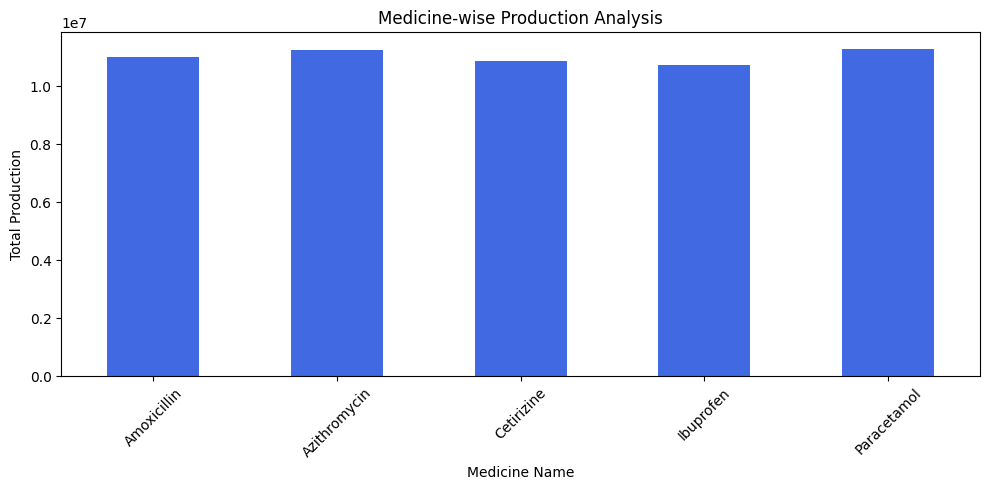

In [ ]:
plt.figure(figsize=(10, 5))

df.groupby("Medicine_Name")["Production_Quantity"].sum().plot(
    kind="bar", color="royalblue"
)

plt.title("Medicine-wise Production Analysis")
plt.xlabel("Medicine Name")
plt.ylabel("Total Production")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

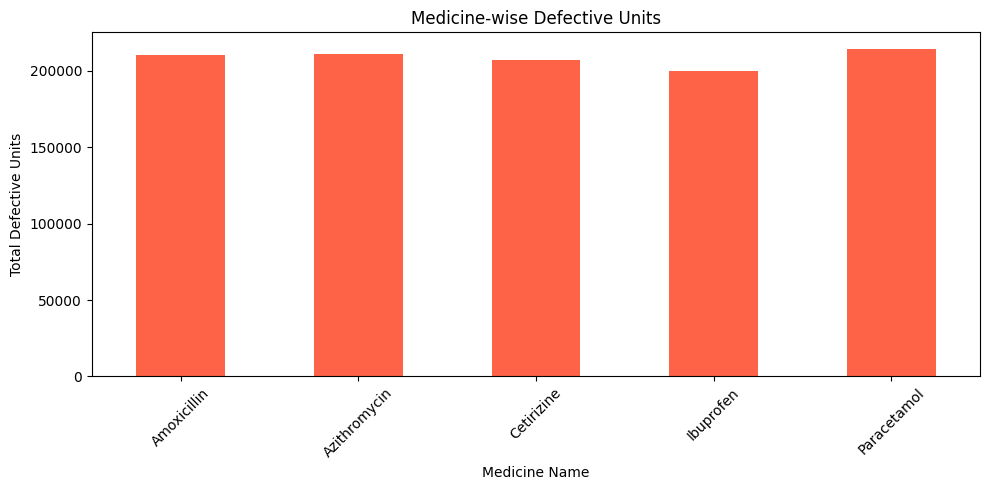

In [ ]:
plt.figure(figsize=(10, 5))

df.groupby("Medicine_Name")["Defective_Units"].sum().plot(
    kind="bar", color="tomato"
)

plt.title("Medicine-wise Defective Units")
plt.xlabel("Medicine Name")
plt.ylabel("Total Defective Units")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

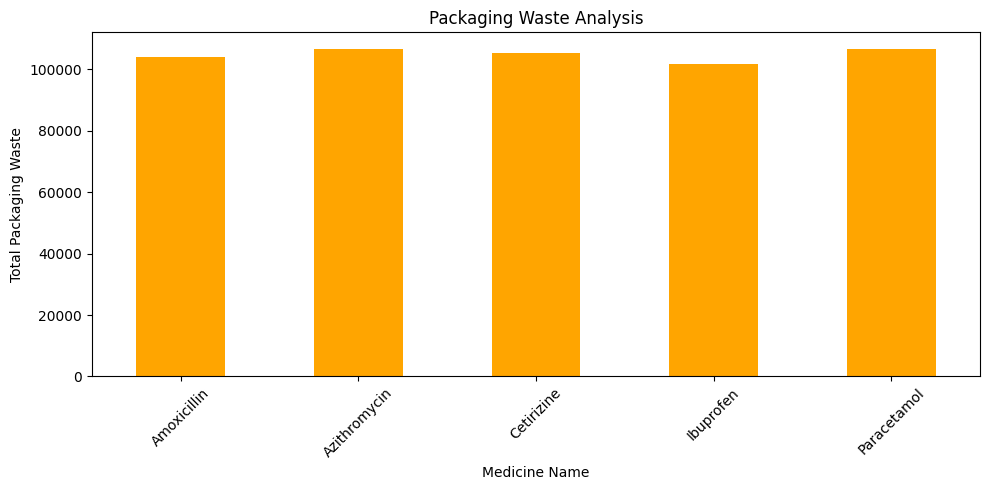

In [ ]:
plt.figure(figsize=(10, 5))

df.groupby("Medicine_Name")["Packaging_Waste"].sum().plot(
    kind="bar", color="orange"
)

plt.title("Packaging Waste Analysis")
plt.xlabel("Medicine Name")
plt.ylabel("Total Packaging Waste")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

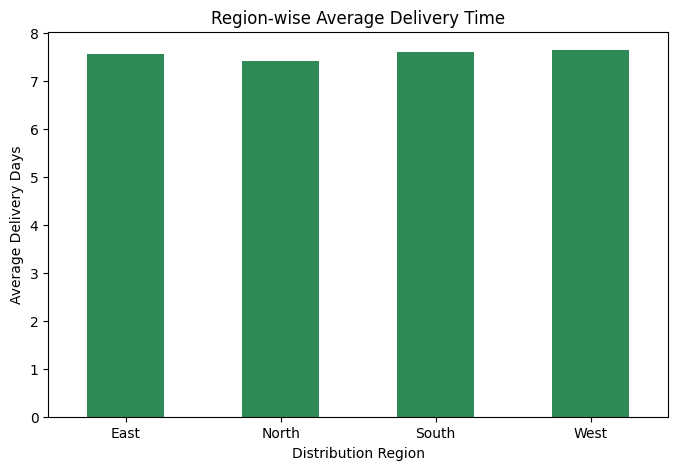

In [ ]:
plt.figure(figsize=(8, 5))

df.groupby("Distribution_Region")["Delivery_Time_Days"].mean().plot(
    kind="bar", color="seagreen"
)

plt.title("Region-wise Average Delivery Time")
plt.xlabel("Distribution Region")
plt.ylabel("Average Delivery Days")
plt.xticks(rotation=0)
plt.show()

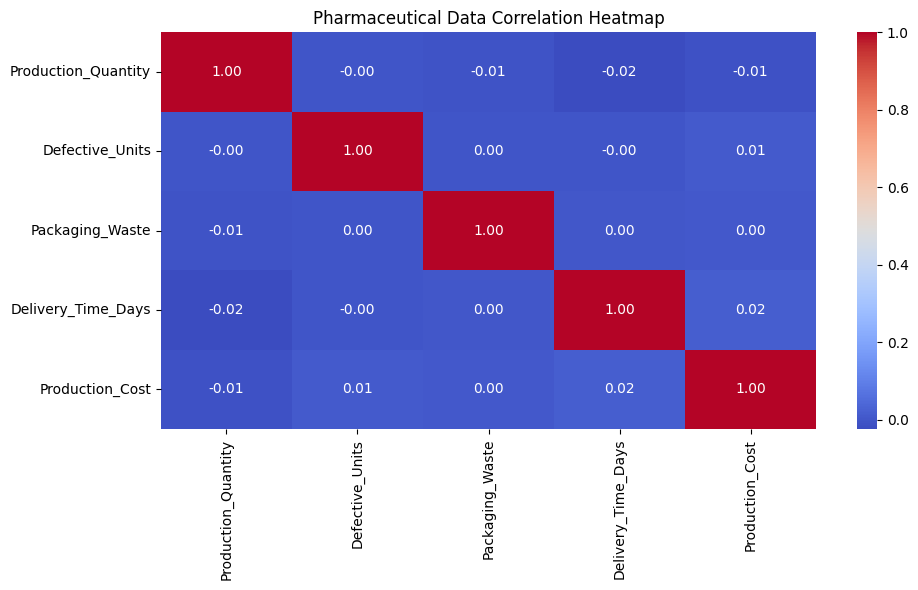

In [ ]:
plt.figure(figsize=(10, 6))

sns.heatmap(
    df.select_dtypes(include="number").corr(),
    annot=True,
    cmap="coolwarm",
    fmt=".2f"
)

plt.title("Pharmaceutical Data Correlation Heatmap")
plt.tight_layout()
plt.show()

In [ ]:
df["Packaging_Quantity"] = (
    df["Production_Quantity"]
    - df["Defective_Units"]
    - df["Packaging_Waste"]
)

df.head()

,Medicine_Name,Production_Quantity,Defective_Units,Packaging_Waste,Delivery_Time_Days,Production_Cost,Distribution_Region,Packaging_Quantity
0,Cetirizine,9953,64,25,2,19337,North,9864
1,Azithromycin,9381,52,96,10,35668,West,9233
2,Ibuprofen,7854,59,68,10,32683,East,7727
3,Azithromycin,1755,15,72,5,12218,East,1668
4,Azithromycin,5931,170,97,8,47126,West,5664


In [ ]:
df["Yield_Percentage"] = (
    df["Packaging_Quantity"] / df["Production_Quantity"]
) * 100

df["Yield_Percentage"] = df["Yield_Percentage"].round(2)

df.head()

,Medicine_Name,Production_Quantity,Defective_Units,Packaging_Waste,Delivery_Time_Days,Production_Cost,Distribution_Region,Packaging_Quantity,Yield_Percentage
0,Cetirizine,9953,64,25,2,19337,North,9864,99.11
1,Azithromycin,9381,52,96,10,35668,West,9233,98.42
2,Ibuprofen,7854,59,68,10,32683,East,7727,98.38
3,Azithromycin,1755,15,72,5,12218,East,1668,95.04
4,Azithromycin,5931,170,97,8,47126,West,5664,95.50


In [ ]:
overall_yield = (
    df["Packaging_Quantity"].sum()
    / df["Production_Quantity"].sum()
) * 100

print("Overall Packaging Yield:", round(overall_yield, 2), "%")

Overall Packaging Yield: 97.15 %


In [ ]:
yield_analysis = df.groupby("Medicine_Name")[
    "Yield_Percentage"
].mean().round(2)

print(yield_analysis)

Medicine_Name
Amoxicillin     95.96
Azithromycin    96.02
Cetirizine      95.86
Ibuprofen       96.01
Paracetamol     95.99
Name: Yield_Percentage, dtype: float64


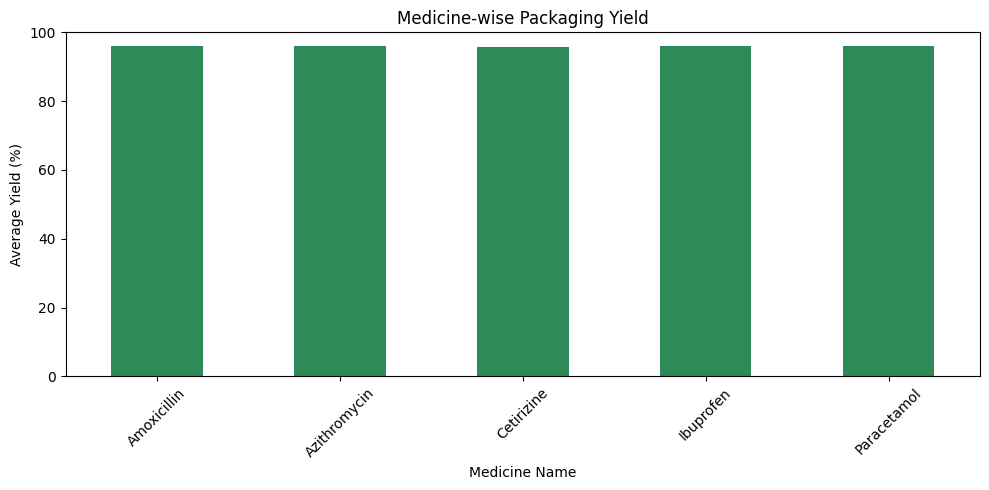

In [ ]:
plt.figure(figsize=(10, 5))

yield_analysis.plot(kind="bar", color="seagreen")

plt.title("Medicine-wise Packaging Yield")
plt.xlabel("Medicine Name")
plt.ylabel("Average Yield (%)")
plt.xticks(rotation=45)
plt.ylim(0, 100)
plt.tight_layout()
plt.show()

In [ ]:
low_yield = df[df["Yield_Percentage"] < 95]

print("Low Yield Records:", len(low_yield))

low_yield.head()

Low Yield Records: 2427


,Medicine_Name,Production_Quantity,Defective_Units,Packaging_Waste,Delivery_Time_Days,Production_Cost,Distribution_Region,Packaging_Quantity,Yield_Percentage
7,Ibuprofen,5060,176,91,9,47931,North,4793,94.72
12,Azithromycin,2689,190,13,3,7733,East,2486,92.45
17,Azithromycin,2145,194,13,12,38575,East,1938,90.35
21,Azithromycin,1560,170,93,11,39042,West,1297,83.14
22,Cetirizine,2912,144,74,8,38756,West,2694,92.51


In [ ]:
df.to_csv("pharmaceutical_yield_analysis.csv", index=False)

print("Yield analysis completed successfully!")

Yield analysis completed successfully!


In [ ]:
df["Waste_Percentage"] = (
    df["Packaging_Waste"] / df["Production_Quantity"]
) * 100

df["Waste_Percentage"] = df["Waste_Percentage"].round(2)

df.head()

,Medicine_Name,Production_Quantity,Defective_Units,Packaging_Waste,Delivery_Time_Days,Production_Cost,Distribution_Region,Packaging_Quantity,Yield_Percentage,Waste_Percentage
0,Cetirizine,9953,64,25,2,19337,North,9864,99.11,0.25
1,Azithromycin,9381,52,96,10,35668,West,9233,98.42,1.02
2,Ibuprofen,7854,59,68,10,32683,East,7727,98.38,0.87
3,Azithromycin,1755,15,72,5,12218,East,1668,95.04,4.10
4,Azithromycin,5931,170,97,8,47126,West,5664,95.50,1.64


In [ ]:
print("Total Packaging Waste:", df["Packaging_Waste"].sum())

print("Average Waste Percentage:",
      round(df["Waste_Percentage"].mean(), 2), "%")

Total Packaging Waste: 524747
Average Waste Percentage: 1.35 %


In [ ]:
waste_analysis = df.groupby("Medicine_Name")[
    "Waste_Percentage"
].mean().sort_values(ascending=False)

print(waste_analysis.round(2))

Medicine_Name
Cetirizine      1.39
Amoxicillin     1.35
Ibuprofen       1.34
Azithromycin    1.34
Paracetamol     1.34
Name: Waste_Percentage, dtype: float64


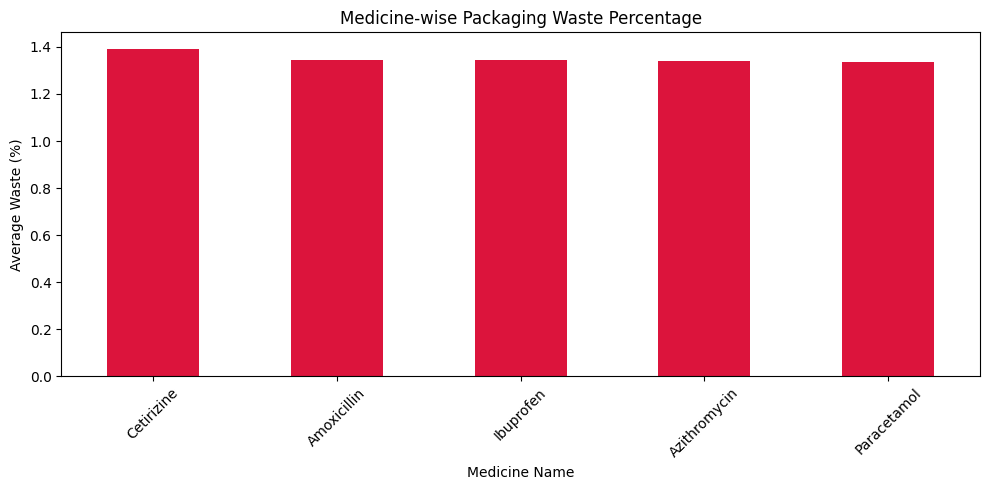

In [ ]:
plt.figure(figsize=(10, 5))

waste_analysis.plot(kind="bar", color="crimson")

plt.title("Medicine-wise Packaging Waste Percentage")
plt.xlabel("Medicine Name")
plt.ylabel("Average Waste (%)")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [ ]:
high_waste = df[df["Waste_Percentage"] > 2]

print("High Waste Records:", len(high_waste))

high_waste.head()

High Waste Records: 1870


,Medicine_Name,Production_Quantity,Defective_Units,Packaging_Waste,Delivery_Time_Days,Production_Cost,Distribution_Region,Packaging_Quantity,Yield_Percentage,Waste_Percentage
3,Azithromycin,1755,15,72,5,12218,East,1668,95.04,4.10
13,Amoxicillin,2316,43,62,1,29838,West,2211,95.47,2.68
21,Azithromycin,1560,170,93,11,39042,West,1297,83.14,5.96
22,Cetirizine,2912,144,74,8,38756,West,2694,92.51,2.54
24,Paracetamol,1296,176,86,6,21401,West,1034,79.78,6.64


In [ ]:
current_waste = df["Packaging_Waste"].sum()

reduced_waste = current_waste * 0.80

saved_units = current_waste - reduced_waste

print("Current Waste:", current_waste)
print("Estimated Waste After Optimization:", round(reduced_waste))
print("Potential Units Saved:", round(saved_units))

Current Waste: 524747
Estimated Waste After Optimization: 419798
Potential Units Saved: 104949


In [ ]:
df.to_csv("pharmaceutical_waste_analysis.csv", index=False)

print("Packaging Waste Analysis Completed!")

Packaging Waste Analysis Completed!


In [ ]:
average_delivery = df["Delivery_Time_Days"].mean()

print("Average Delivery Time:",
      round(average_delivery, 2), "Days")

Average Delivery Time: 7.56 Days


In [ ]:
region_analysis = df.groupby("Distribution_Region").agg({
    "Production_Quantity": "sum",
    "Packaging_Quantity": "sum",
    "Delivery_Time_Days": "mean",
    "Production_Cost": "sum"
})

region_analysis.round(2)

,Production_Quantity,Packaging_Quantity,Delivery_Time_Days,Production_Cost
Distribution_Region,,,,
East,13401271,13015132,7.57,68079713
North,14230916,13828838,7.43,71208286
South,13889983,13494918,7.60,69619697
West,13562524,13178126,7.65,67403825


In [ ]:
delayed_orders = df[df["Delivery_Time_Days"] > 10]

print("Total Delayed Deliveries:", len(delayed_orders))

delay_percentage = (len(delayed_orders) / len(df)) * 100

print("Delayed Delivery Percentage:",
      round(delay_percentage, 2), "%")

Total Delayed Deliveries: 2856
Delayed Delivery Percentage: 28.56 %


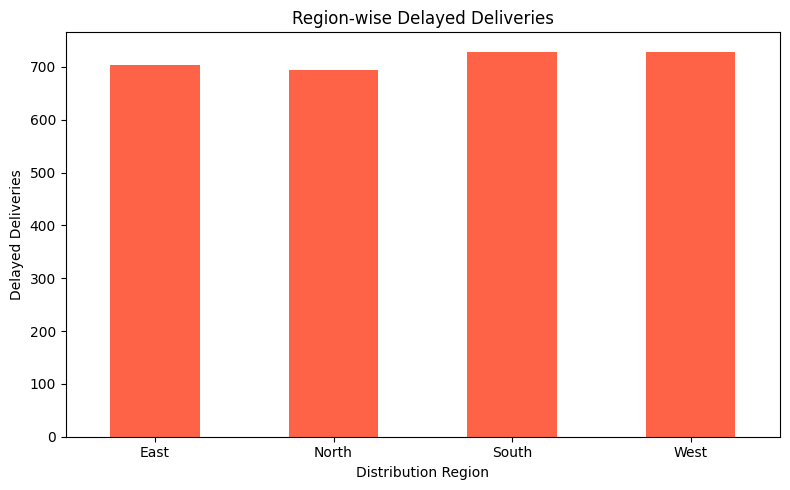

In [ ]:
plt.figure(figsize=(8, 5))

delayed_orders.groupby("Distribution_Region").size().plot(
    kind="bar", color="tomato"
)

plt.title("Region-wise Delayed Deliveries")
plt.xlabel("Distribution Region")
plt.ylabel("Delayed Deliveries")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

In [ ]:
df["Cost_Per_Unit"] = (
    df["Production_Cost"] / df["Production_Quantity"]
).round(2)

df.head()

,Medicine_Name,Production_Quantity,Defective_Units,Packaging_Waste,Delivery_Time_Days,Production_Cost,Distribution_Region,Packaging_Quantity,Yield_Percentage,Waste_Percentage,Cost_Per_Unit
0,Cetirizine,9953,64,25,2,19337,North,9864,99.11,0.25,1.94
1,Azithromycin,9381,52,96,10,35668,West,9233,98.42,1.02,3.80
2,Ibuprofen,7854,59,68,10,32683,East,7727,98.38,0.87,4.16
3,Azithromycin,1755,15,72,5,12218,East,1668,95.04,4.10,6.96
4,Azithromycin,5931,170,97,8,47126,West,5664,95.50,1.64,7.95


In [ ]:
bottlenecks = df[
    (df["Delivery_Time_Days"] > 10) |
    (df["Yield_Percentage"] < 95) |
    (df["Waste_Percentage"] > 2)
]

print("Total Bottleneck Records:", len(bottlenecks))

bottlenecks.head()

Total Bottleneck Records: 4797


,Medicine_Name,Production_Quantity,Defective_Units,Packaging_Waste,Delivery_Time_Days,Production_Cost,Distribution_Region,Packaging_Quantity,Yield_Percentage,Waste_Percentage,Cost_Per_Unit
3,Azithromycin,1755,15,72,5,12218,East,1668,95.04,4.10,6.96
7,Ibuprofen,5060,176,91,9,47931,North,4793,94.72,1.80,9.47
12,Azithromycin,2689,190,13,3,7733,East,2486,92.45,0.48,2.88
13,Amoxicillin,2316,43,62,1,29838,West,2211,95.47,2.68,12.88
17,Azithromycin,2145,194,13,12,38575,East,1938,90.35,0.61,17.98


In [ ]:
optimized_delivery = average_delivery * 0.80

print("Current Average Delivery:",
      round(average_delivery, 2), "Days")

print("Target Average Delivery:",
      round(optimized_delivery, 2), "Days")

print("Potential Time Saved:",
      round(average_delivery - optimized_delivery, 2), "Days")

Current Average Delivery: 7.56 Days
Target Average Delivery: 6.05 Days
Potential Time Saved: 1.51 Days


In [ ]:
df.to_csv("pharmaceutical_supply_chain_analysis.csv", index=False)

print("Supply Chain Analysis Completed Successfully!")

Supply Chain Analysis Completed Successfully!


In [ ]:
df["Material_Required_KG"] = (
    df["Production_Quantity"] * 0.05
).round(2)

df.head()

,Medicine_Name,Production_Quantity,Defective_Units,Packaging_Waste,Delivery_Time_Days,Production_Cost,Distribution_Region,Packaging_Quantity,Yield_Percentage,Waste_Percentage,Cost_Per_Unit,Material_Required_KG
0,Cetirizine,9953,64,25,2,19337,North,9864,99.11,0.25,1.94,497.65
1,Azithromycin,9381,52,96,10,35668,West,9233,98.42,1.02,3.80,469.05
2,Ibuprofen,7854,59,68,10,32683,East,7727,98.38,0.87,4.16,392.70
3,Azithromycin,1755,15,72,5,12218,East,1668,95.04,4.10,6.96,87.75
4,Azithromycin,5931,170,97,8,47126,West,5664,95.50,1.64,7.95,296.55


In [ ]:
df["Packaging_Material_Required"] = (
    df["Production_Quantity"] - df["Defective_Units"]
)

df.head()

,Medicine_Name,Production_Quantity,Defective_Units,Packaging_Waste,Delivery_Time_Days,Production_Cost,Distribution_Region,Packaging_Quantity,Yield_Percentage,Waste_Percentage,Cost_Per_Unit,Material_Required_KG,Packaging_Material_Required
0,Cetirizine,9953,64,25,2,19337,North,9864,99.11,0.25,1.94,497.65,9889
1,Azithromycin,9381,52,96,10,35668,West,9233,98.42,1.02,3.80,469.05,9329
2,Ibuprofen,7854,59,68,10,32683,East,7727,98.38,0.87,4.16,392.70,7795
3,Azithromycin,1755,15,72,5,12218,East,1668,95.04,4.10,6.96,87.75,1740
4,Azithromycin,5931,170,97,8,47126,West,5664,95.50,1.64,7.95,296.55,5761


In [ ]:
print("Total Raw Material Required:",
      round(df["Material_Required_KG"].sum(), 2), "KG")

print("Total Packaging Material Required:",
      df["Packaging_Material_Required"].sum(), "Units")

Total Raw Material Required: 2754234.7 KG
Total Packaging Material Required: 54041761 Units


In [ ]:
material_analysis = df.groupby("Medicine_Name")[
    "Material_Required_KG"
].sum().round(2)

print(material_analysis)

Medicine_Name
Amoxicillin     549894.30
Azithromycin    561467.80
Cetirizine      542689.35
Ibuprofen       535675.30
Paracetamol     564507.95
Name: Material_Required_KG, dtype: float64


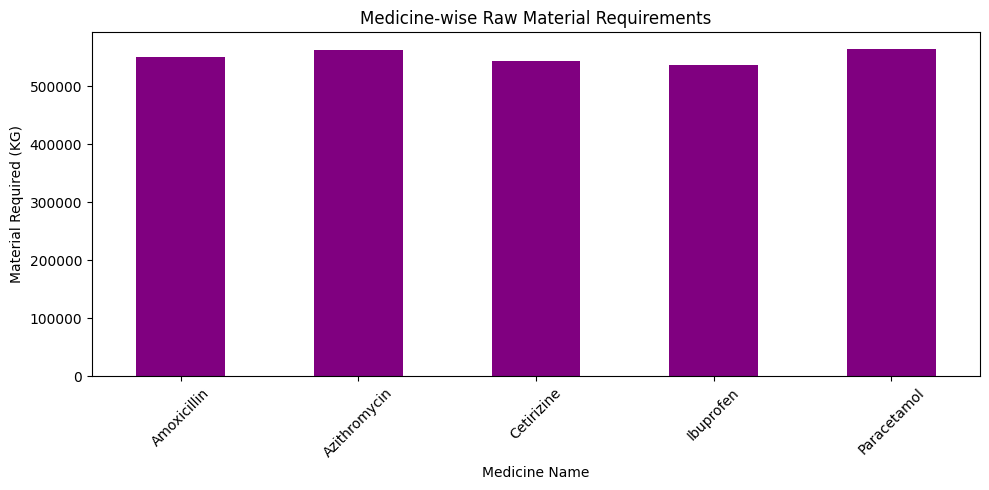

In [ ]:
plt.figure(figsize=(10, 5))

material_analysis.plot(kind="bar", color="purple")

plt.title("Medicine-wise Raw Material Requirements")
plt.xlabel("Medicine Name")
plt.ylabel("Material Required (KG)")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [ ]:
current_material = df["Material_Required_KG"].sum()

future_material = current_material * 1.15

additional_material = future_material - current_material

print("Current Requirement:",
      round(current_material, 2), "KG")

print("Future Requirement:",
      round(future_material, 2), "KG")

print("Additional Material Required:",
      round(additional_material, 2), "KG")

Current Requirement: 2754234.7 KG
Future Requirement: 3167369.9 KG
Additional Material Required: 413135.2 KG


In [ ]:
df.to_csv("pharmaceutical_material_analysis.csv", index=False)

print("Material Requirement Analysis Completed Successfully!")

Material Requirement Analysis Completed Successfully!


In [ ]:
X = df[[
    "Production_Quantity",
    "Medicine_Name",
    "Distribution_Region"
]]

X = pd.get_dummies(X, dtype=int)

y = df["Yield_Percentage"]

print("Features and target selected successfully!")

Features and target selected successfully!


In [ ]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

print("Training Records:", len(X_train))
print("Testing Records:", len(X_test))

Training Records: 8000
Testing Records: 2000


In [ ]:
model = RandomForestRegressor(
    n_estimators=100,
    random_state=42,
    min_samples_leaf=10,
    n_jobs=-1
)

print("Random Forest Model Created!")

Random Forest Model Created!


In [ ]:
model.fit(X_train, y_train)

print("Model Trained Successfully!")

Model Trained Successfully!


In [ ]:
y_pred = model.predict(X_test)

print("Prediction Completed Successfully!")

print(y_pred[:10])

Prediction Completed Successfully!
[94.77416915 95.86243173 92.06302215 98.07868346 98.44712008 94.53303042
 98.35325913 92.73094647 98.21377646 96.12839307]


In [ ]:
results = pd.DataFrame({
    "Actual_Yield": y_test.values,
    "Predicted_Yield": y_pred
})

results.round(2).head(10)

,Actual_Yield,Predicted_Yield
0,92.80,94.77
1,95.13,95.86
2,89.96,92.06
3,97.98,98.08
4,98.92,98.45
5,91.97,94.53
6,99.17,98.35
7,92.97,92.73
8,98.51,98.21
9,95.99,96.13


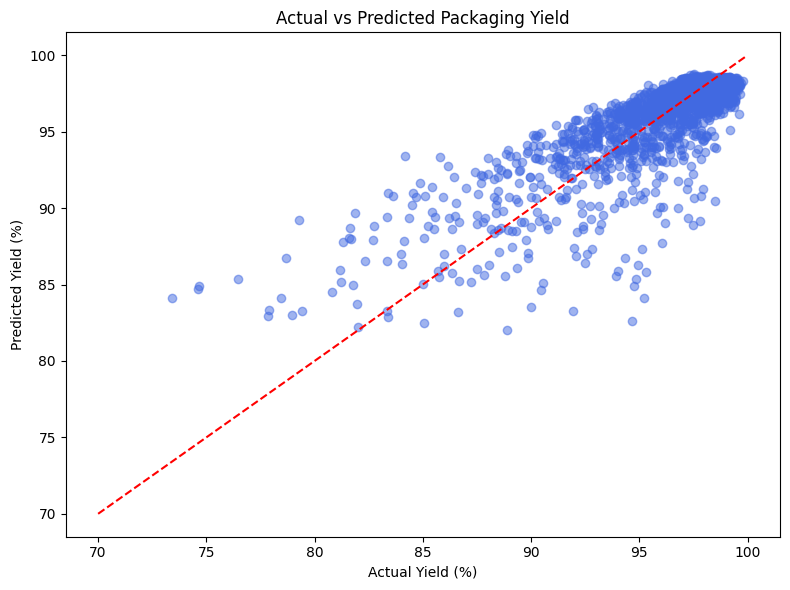

In [ ]:
plt.figure(figsize=(8, 6))

plt.scatter(y_test, y_pred, alpha=0.5, color="royalblue")

plt.plot([70, 100], [70, 100], "r--")

plt.xlabel("Actual Yield (%)")
plt.ylabel("Predicted Yield (%)")
plt.title("Actual vs Predicted Packaging Yield")
plt.tight_layout()
plt.show()

In [ ]:
import joblib

joblib.dump(model, "packaging_yield_model.pkl")

print("Machine Learning Model Saved Successfully!")

Machine Learning Model Saved Successfully!


In [ ]:
mae = mean_absolute_error(y_test, y_pred)

print("MAE:", round(mae, 4))

MAE: 1.3067


In [ ]:
rmse = np.sqrt(mean_squared_error(y_test, y_pred))

print("RMSE:", round(rmse, 4))

RMSE: 1.9772


In [ ]:
from sklearn.metrics import mean_absolute_percentage_error

mape = mean_absolute_percentage_error(y_test, y_pred) * 100

print("MAPE:", round(mape, 2), "%")

MAPE: 1.4 %


In [ ]:
r2 = r2_score(y_test, y_pred)

print("R2 Score:", round(r2, 4))

R2 Score: 0.6721


In [ ]:
performance = pd.DataFrame({
    "Metric": ["MAE", "RMSE", "MAPE (%)", "R2 Score"],
    "Value": [mae, rmse, mape, r2]
})

performance.round(4)

,Metric,Value
0,MAE,1.3067
1,RMSE,1.9772
2,MAPE (%),1.3969
3,R2 Score,0.6721


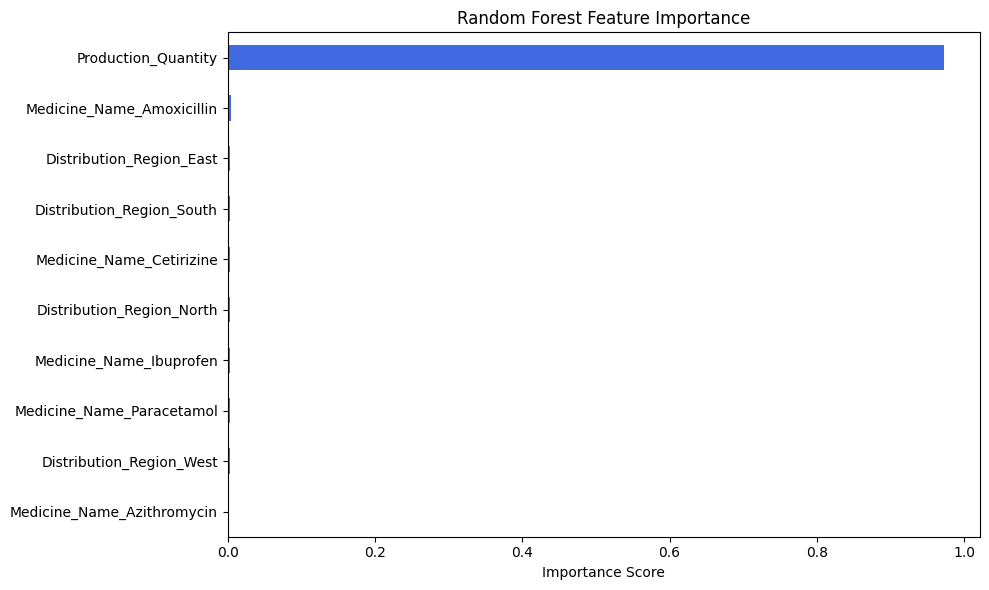

In [ ]:
importance = pd.Series(
    model.feature_importances_,
    index=X.columns
).sort_values(ascending=True)

plt.figure(figsize=(10, 6))

importance.plot(kind="barh", color="royalblue")

plt.title("Random Forest Feature Importance")
plt.xlabel("Importance Score")
plt.tight_layout()
plt.show()

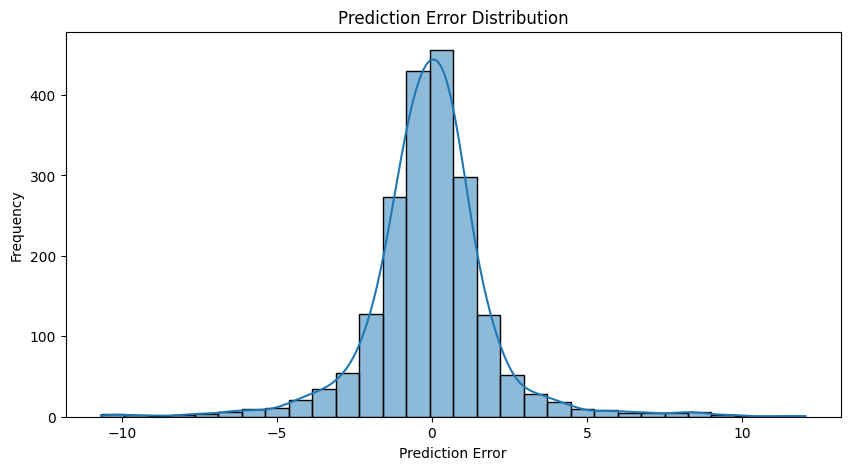

In [ ]:
errors = y_test.values - y_pred

plt.figure(figsize=(10, 5))

sns.histplot(errors, bins=30, kde=True)

plt.title("Prediction Error Distribution")
plt.xlabel("Prediction Error")
plt.ylabel("Frequency")
plt.show()

In [ ]:
performance.to_csv("model_performance.csv", index=False)

results.to_csv("yield_prediction_results.csv", index=False)

df.to_csv("final_pharmaceutical_dataset.csv", index=False)

print("All results saved successfully!")

All results saved successfully!


In [ ]:
from google.colab import files

files.download("final_pharmaceutical_dataset.csv")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
import plotly.express as px
import plotly.graph_objects as go
from plotly.subplots import make_subplots

print("Plotly imported successfully!")

Plotly imported successfully!


In [ ]:
fig = make_subplots(
    rows=2,
    cols=3,
    specs=[
        [{"type": "indicator"}] * 3,
        [{"type": "indicator"}] * 3
    ]
)

kpis = [
    ("Total Production", df["Production_Quantity"].sum(), ""),
    ("Successful Packaging", df["Packaging_Quantity"].sum(), ""),
    ("Overall Yield", overall_yield, "%"),
    ("Packaging Waste", df["Packaging_Waste"].sum(), ""),
    ("Average Delivery Time", df["Delivery_Time_Days"].mean(), " Days"),
    ("Total Production Cost", df["Production_Cost"].sum(), "")
]

for i, (title, value, suffix) in enumerate(kpis):
    fig.add_trace(
        go.Indicator(
            mode="number",
            value=value,
            title={"text": title},
            number={"suffix": suffix, "valueformat": ",.2f"}
        ),
        row=i // 3 + 1,
        col=i % 3 + 1
    )

fig.update_layout(
    title="Pharmaceutical Supply Chain Dashboard",
    template="plotly_dark",
    height=500
)

fig.show()

In [ ]:
fig.write_html("pharmaceutical_dashboard.html")

print("Dashboard saved successfully!")

Dashboard saved successfully!


In [ ]:
from google.colab import files

files.download("pharmaceutical_dashboard.html")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
production = df.groupby("Medicine_Name", as_index=False)[
    "Production_Quantity"
].sum()

fig1 = px.bar(
    production,
    x="Medicine_Name",
    y="Production_Quantity",
    color="Medicine_Name",
    title="Medicine-wise Production",
    template="plotly_dark"
)

fig1.show()

In [ ]:
yield_data = df.groupby("Medicine_Name", as_index=False)[
    "Yield_Percentage"
].mean()

fig2 = px.bar(
    yield_data,
    x="Medicine_Name",
    y="Yield_Percentage",
    color="Medicine_Name",
    title="Medicine-wise Packaging Yield",
    template="plotly_dark"
)

fig2.show()

In [ ]:
fig3 = px.pie(
    df,
    names="Distribution_Region",
    values="Packaging_Quantity",
    hole=0.5,
    title="Regional Distribution Analysis",
    template="plotly_dark"
)

fig3.show()

In [ ]:
waste = df.groupby("Medicine_Name", as_index=False)[
    "Packaging_Waste"
].sum()

fig4 = px.bar(
    waste,
    x="Medicine_Name",
    y="Packaging_Waste",
    color="Medicine_Name",
    title="Packaging Waste Analysis",
    template="plotly_dark"
)

fig4.show()

In [ ]:
fig5 = px.box(
    df,
    x="Distribution_Region",
    y="Delivery_Time_Days",
    color="Distribution_Region",
    title="Regional Delivery Performance",
    template="plotly_dark"
)

fig5.show()

In [ ]:
import plotly.io as pio

html = """
<!DOCTYPE html>
<html>
<head>
<title>Pharmaceutical Supply Chain Dashboard</title>

<style>
body {
    background-color: #0f172a;
    color: white;
    font-family: Arial, sans-serif;
    margin: 30px;
}

h1, h2 {
    text-align: center;
}

.subtitle {
    text-align: center;
    color: #94a3b8;
}

.dashboard {
    display: grid;
    grid-template-columns: repeat(2, minmax(0, 1fr));
    gap: 20px;
}

.chart {
    background-color: #1e293b;
    padding: 15px;
    border-radius: 12px;
}

@media (max-width: 800px) {
    .dashboard {
        grid-template-columns: 1fr;
    }
}
</style>
</head>

<body>

<h1>Pharmaceutical Supply Chain Dashboard</h1>

<p class="subtitle">
Supply Chain Optimization & Predictive Yield Analytics
</p>

<p class="subtitle">
Demonstration using Synthetic Pharmaceutical Data
</p>
"""

html += pio.to_html(
    fig, full_html=False, include_plotlyjs=True
)

html += '<div class="dashboard">'

for chart in [fig1, fig2, fig3, fig4, fig5]:
    html += '<div class="chart">'
    html += pio.to_html(
        chart,
        full_html=False,
        include_plotlyjs=False
    )
    html += '</div>'

html += """
</div>

<h2>Supply Chain & Yield Analytics Project</h2>

</body>
</html>
"""

with open("Final_Pharmaceutical_Dashboard.html", "w",
          encoding="utf-8") as file:
    file.write(html)

print("Final Dashboard Created Successfully!")

Final Dashboard Created Successfully!


In [ ]:
from google.colab import files

files.download("Final_Pharmaceutical_Dashboard.html")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
import ipywidgets as widgets
from IPython.display import display, clear_output

In [ ]:
medicine_filter = widgets.Dropdown(
    options=["All"] + sorted(df["Medicine_Name"].unique().tolist()),
    description="Medicine:",
    value="All"
)

region_filter = widgets.Dropdown(
    options=["All"] + sorted(df["Distribution_Region"].unique().tolist()),
    description="Region:",
    value="All"
)

display(medicine_filter, region_filter)

Dropdown(description='Medicine:', options=('All', 'Amoxicillin', 'Azithromycin', 'Cetirizine', 'Ibuprofen', 'P…

Dropdown(description='Region:', options=('All', 'East', 'North', 'South', 'West'), value='All')

In [ ]:
def update_dashboard(medicine, region):

    filtered_df = df.copy()

    if medicine != "All":
        filtered_df = filtered_df[
            filtered_df["Medicine_Name"] == medicine
        ]

    if region != "All":
        filtered_df = filtered_df[
            filtered_df["Distribution_Region"] == region
        ]

    print("Total Production:",
          filtered_df["Production_Quantity"].sum())

    print("Packaging Yield:",
          round(
              filtered_df["Packaging_Quantity"].sum()
              / filtered_df["Production_Quantity"].sum() * 100, 2
          ), "%")

    print("Total Packaging Waste:",
          filtered_df["Packaging_Waste"].sum())

    print("Average Delivery Time:",
          round(filtered_df["Delivery_Time_Days"].mean(), 2),
          "Days")

    chart_data = filtered_df.groupby(
        "Medicine_Name", as_index=False
    )["Production_Quantity"].sum()

    chart = px.bar(
        chart_data,
        x="Medicine_Name",
        y="Production_Quantity",
        color="Medicine_Name",
        title="Filtered Production Analysis",
        template="plotly_dark"
    )

    chart.show()

widgets.interact(
    update_dashboard,
    medicine=medicine_filter,
    region=region_filter
)

interactive(children=(Dropdown(description='Medicine:', options=('All', 'Amoxicillin', 'Azithromycin', 'Cetiri…

<function __main__.update_dashboard(medicine, region)>

In [ ]:
print("===== BUSINESS INSIGHTS =====")

print("\nHighest Production Medicine:")
print(df.groupby("Medicine_Name")["Production_Quantity"].sum().idxmax())

print("\nHighest Packaging Yield Medicine:")
print(df.groupby("Medicine_Name")["Yield_Percentage"].mean().idxmax())

print("\nHighest Waste Percentage Medicine:")
print(df.groupby("Medicine_Name")["Waste_Percentage"].mean().idxmax())

print("\nRegion with Highest Average Delivery Time:")
print(df.groupby("Distribution_Region")["Delivery_Time_Days"].mean().idxmax())

print("\nOverall Packaging Yield:", round(overall_yield, 2), "%")

print("\nDelayed Deliveries:", len(delayed_orders))

print("\nPotential Bottleneck Records:", len(bottlenecks))

===== BUSINESS INSIGHTS =====

Highest Production Medicine:
Paracetamol

Highest Packaging Yield Medicine:
Azithromycin

Highest Waste Percentage Medicine:
Cetirizine

Region with Highest Average Delivery Time:
West

Overall Packaging Yield: 97.15 %

Delayed Deliveries: 2856

Potential Bottleneck Records: 4797


Business Recommendations

1. Packaging Yield Optimization: Prioritize batches with packaging yield below 95% for further investigation.
2. Waste Reduction: Investigate high-waste batches and evaluate packaging process improvements.
3. Supply Chain Optimization: Review distribution regions with longer delivery times to identify potential logistics bottlenecks.
4. Material Planning: Use production demand estimates to improve raw material and packaging inventory planning.
5. Predictive Analytics: Evaluate machine learning models for early identification of low-yield production batches.
6. Performance Monitoring: Use interactive dashboards to monitor production, packaging yield, waste, and delivery performance.

These recommendations are based on synthetic pharmaceutical data and require validation using actual operational data before implementation.

In [ ]:
summary = pd.DataFrame({
    "Business KPI": [
        "Total Records",
        "Total Production",
        "Successful Packaging",
        "Overall Yield (%)",
        "Total Packaging Waste",
        "Average Delivery Days",
        "Delayed Deliveries",
        "Potential Bottlenecks"
    ],
    "Value": [
        len(df),
        df["Production_Quantity"].sum(),
        df["Packaging_Quantity"].sum(),
        round(overall_yield, 2),
        df["Packaging_Waste"].sum(),
        round(average_delivery, 2),
        len(delayed_orders),
        len(bottlenecks)
    ]
})

summary

,Business KPI,Value
0,Total Records,10000.00
1,Total Production,55084694.00
2,Successful Packaging,53517014.00
3,Overall Yield (%),97.15
4,Total Packaging Waste,524747.00
5,Average Delivery Days,7.56
6,Delayed Deliveries,2856.00
7,Potential Bottlenecks,4797.00


In [ ]:
summary.to_csv("business_insights.csv", index=False)

print("Business Insights Saved Successfully!")

Business Insights Saved Successfully!


In [ ]:
import zipfile
from google.colab import files

project_files = [
    "final_pharmaceutical_dataset.csv",
    "Final_Pharmaceutical_Dashboard.html",
    "packaging_yield_model.pkl",
    "model_performance.csv",
    "yield_prediction_results.csv",
    "business_insights.csv"
]

with zipfile.ZipFile("Pharmaceutical_Project.zip", "w") as z:
    for file in project_files:
        z.write(file)

files.download("Pharmaceutical_Project.zip")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
%%writefile requirements.txt
pandas
numpy
matplotlib
seaborn
scikit-learn
plotly
ipywidgets
joblib

Writing requirements.txt


In [ ]:
files.download("requirements.txt")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
from google.colab import files

files.download("packaging_yield_model.pkl")
files.download("model_performance.csv")
files.download("yield_prediction_results.csv")
files.download("business_insights.csv")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>